# Checkpoint Three: Exploratory Analysis
**CS 418 · Socioeconomic Health Disparities · Group: Anirudh Gupta, Claudia Jimenez, Andrew Mcclendon, Auon Muhammad Naqvi, Jesus Rodriguez**

*(Rubric: 1 profiles · 2 anomalies · 3 distributions · 4 relationships (≥3, incl. the join) · 5 "so what" · 6 "what next")*

In [2]:
# ---- SHARED SETUP: don't edit. Run this first. ---- #
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

pl.Config.set_tbl_cols(-1)

pop    = pl.read_csv("data/Chicago_Community_Population_Data.csv", infer_schema_length=10000)               # primary
air    = pl.read_csv("data/Open_Air_Chicago_Day_Aggregations_sample_20260928.csv", infer_schema_length=10000) # primary
income = pl.read_csv("data/Chicago_Median_Income_By_Community_Area.csv", infer_schema_length=10000)         # secondary
emis   = pl.read_csv("data/CommunityAreas_LocalEmission2019.csv", infer_schema_length=10000)                # secondary

---
# Population dataset
**Owner: Andrew** · Primary dataset: `data/Chicago_Community_Population_Data.csv`

## Step 1 · Profile

In [3]:
print(pop.shape)
print(pop.schema)
pop.glimpse()

(77, 30)
Schema({'ACS Year': Int64, 'Community Area': String, 'Under $25,000': String, '$25,000 to $49,999': String, '$50,000 to $74,999': String, '$75,000 to $125,000': String, '$125,000 +': String, 'Male 0 to 17': String, 'Male 18 to 24': String, 'Male 25 to 34': String, 'Male 35 to 49': String, 'Male 50 to 64': String, 'Male 65+': String, 'Female 0 to 17': String, 'Female 18 to 24': String, 'Female 25 to 34': String, 'Female 35 to 49': String, 'Female 50 to 64': String, 'Female 65 +': String, 'Total Population': String, 'White': String, 'Black or African American': String, 'American Indian or Alaska Native': String, 'Asian': String, 'Native Hawaiian or Pacific Islander': Int64, 'Other Race': String, 'Multiracial': String, 'White Not Hispanic or Latino': String, 'Hispanic or Latino': String, 'Record ID': String})
Rows: 77
Columns: 30
$ ACS Year                            <i64> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023
$ Community Area                      <str> 'ALBA

All listed race had at least one area where their population count was in the single or double digits.

In [4]:
pop.null_count()

ACS Year,Community Area,"Under $25,000","$25,000 to $49,999","$50,000 to $74,999","$75,000 to $125,000","$125,000 +",Male 0 to 17,Male 18 to 24,Male 25 to 34,Male 35 to 49,Male 50 to 64,Male 65+,Female 0 to 17,Female 18 to 24,Female 25 to 34,Female 35 to 49,Female 50 to 64,Female 65 +,Total Population,White,Black or African American,American Indian or Alaska Native,Asian,Native Hawaiian or Pacific Islander,Other Race,Multiracial,White Not Hispanic or Latino,Hispanic or Latino,Record ID
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Good data set, not missing any data

In [5]:
pop.describe()

statistic,ACS Year,Community Area,"Under $25,000","$25,000 to $49,999","$50,000 to $74,999","$75,000 to $125,000","$125,000 +",Male 0 to 17,Male 18 to 24,Male 25 to 34,Male 35 to 49,Male 50 to 64,Male 65+,Female 0 to 17,Female 18 to 24,Female 25 to 34,Female 35 to 49,Female 50 to 64,Female 65 +,Total Population,White,Black or African American,American Indian or Alaska Native,Asian,Native Hawaiian or Pacific Islander,Other Race,Multiracial,White Not Hispanic or Latino,Hispanic or Latino,Record ID
str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str
"""count""",77.0,"""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""",77.0,"""77""","""77""","""77""","""77""","""77"""
"""null_count""",0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""",0.0,"""0""","""0""","""0""","""0""","""0"""
"""mean""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,17.909091,null,null,null,null,null
"""std""",0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,34.429249,null,null,null,null,null
"""min""",2023.0,"""ALBANY PARK""","""1,007""","""1,022""","""1,002""","""1,019""","""1,030""","""1,099""","""1,042""","""1,052""","""1,005""","""1,057""","""1,010""","""1,022""","""1,018""","""1,027""","""1,056""","""1,001""","""1,021""","""100,278""","""1,123""","""1,079""","""0""","""0""",0.0,"""0""","""1,015""","""1,066""","""1,114""","""2023_ALBANY PARK"""
"""25%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,null
"""50%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,null
"""75%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,21.0,null,null,null,null,null
"""max""",2023.0,"""WOODLAWN""","""965""","""997""","""974""","""979""","""988""","""930""","""940""","""933""","""9,920""","""8,110""","""853""","""9,697""","""978""","""978""","""9,695""","""999""","""909""","""91,635""","""908""","""991""","""993""","""991""",171.0,"""993""","""936""","""995""","""981""","""2023_WOODLAWN"""


Not as informative because the min and max dont tell me which area its from

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
| N/A | N/A  | N/A   | N/A  |

## Step 3 · Distributions
One plot per feature that matters to the research questions.

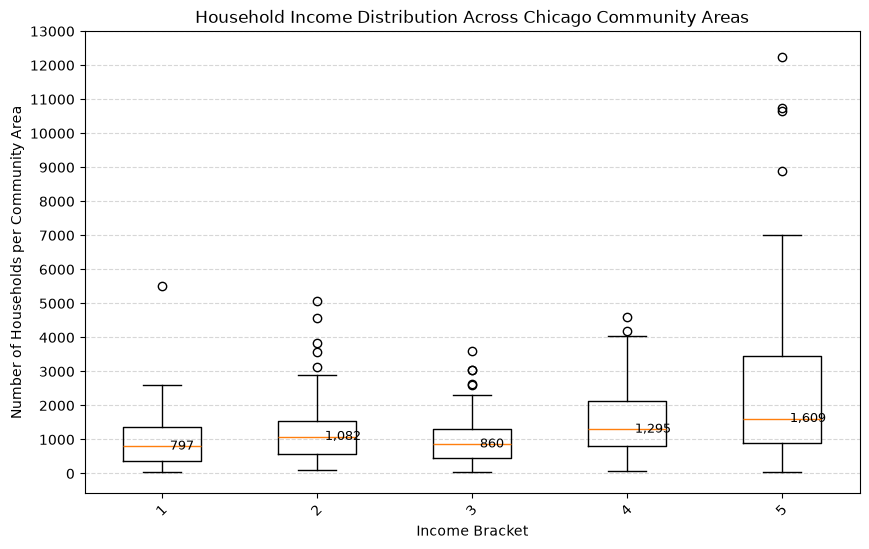

In [6]:
import polars as pl
import matplotlib.pyplot as plt

income_cols = [
    'Under $25,000',
    '$25,000 to $49,999',
    '$50,000 to $74,999',
    '$75,000 to $125,000',
    '$125,000 +'
]

income_labels = [
    'Under $25,000',
    '$25,000 - $49,999',
    '$50,000 - $74,999',
    '$75,000 - $125,000',
    '$125,000+'
]

for col in income_cols:
    if pop.schema[col] == pl.String:
        pop = pop.with_columns(
            pl.col(col)
            .str.replace_all(",", "")
            .cast(pl.Int64)
        )

data = [
    pop[col].drop_nulls().to_list()
    for col in income_cols
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    data,
    label=income_labels
)

medians = [
    pop[col].median()
    for col in income_cols
]

for i, median in enumerate(medians, start=1):
    plt.text(
        i + 0.05,
        median,
        f'{median:,.0f}',
        verticalalignment='center',
        fontsize=9
    )

plt.title("Household Income Distribution Across Chicago Community Areas")
plt.xlabel("Income Bracket")
plt.ylabel("Number of Households per Community Area")

plt.yticks(range(0, 13001, 1000))

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

plt.xticks(rotation=45)


plt.show()

**Distribution 1: [feature name]**
- **Center:** The median househould dont get above 2000 but stil vary but hovers between about 800 and 1600
- **Spread:** 125,000 has the gratest variability and lonest whiskers and the under 250000 have smaller spreads. It seems wealthier income communites tend to group 
- **Skew / shape:** all brackets are right skewed
- **Outliers:** every category has outliers on the increasing side


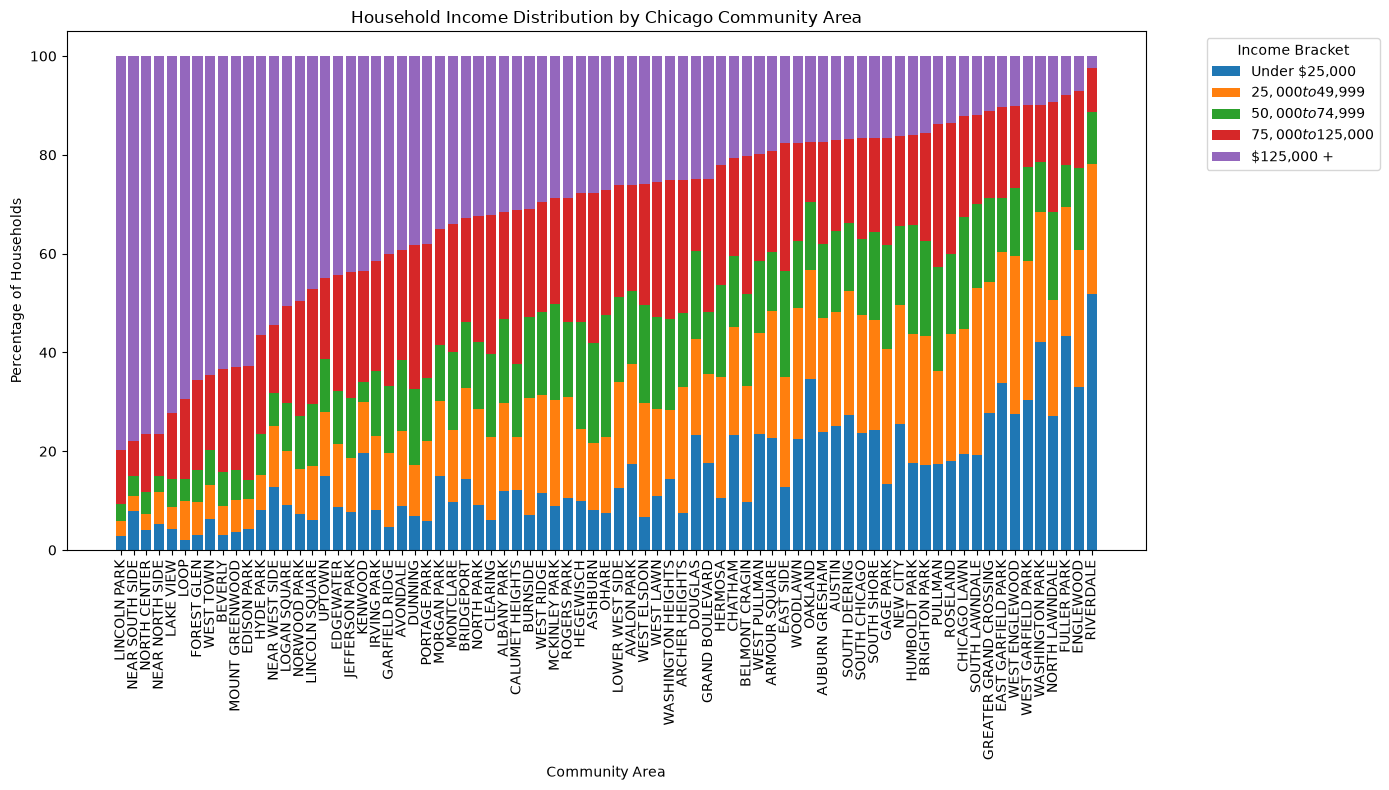

In [7]:


income_cols = [
    'Under $25,000',
    '$25,000 to $49,999',
    '$50,000 to $74,999',
    '$75,000 to $125,000',
    '$125,000 +'
]

income_labels = [
    'Under $25,000',
    '$25,000 - $49,999',
    '$50,000 - $74,999',
    '$75,000 - $125,000',
    '$125,000+'
]



for col in income_cols:
    if pop.schema[col] == pl.String:
        pop = pop.with_columns(
            pl.col(col)
            .str.replace_all(",", "")
            .cast(pl.Int64)
        )


neighborhood_col = "Community Area"


pop = pop.with_columns(
    pl.sum_horizontal(income_cols).alias("Total Households")
)


for col in income_cols:
    pop = pop.with_columns(
        (pl.col(col) / pl.col("Total Households") * 100)
        .alias(col + " %")
    )


pop = pop.sort("$125,000 + %", descending=True)

neighborhoods = pop[neighborhood_col].to_list()

plt.figure(figsize=(14, 8))

bottom = [0] * len(neighborhoods)

for col in income_cols:
    values = pop[col + " %"].to_list()

    plt.bar(
        neighborhoods,
        values,
        bottom=bottom,
        label=col
    )

    bottom = [
        bottom[i] + values[i]
        for i in range(len(values))
    ]

plt.title("Household Income Distribution by Chicago Community Area")
plt.xlabel("Community Area")
plt.ylabel("Percentage of Households")

plt.xticks(rotation=90)

plt.legend(title="Income Bracket", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

---
# Open Air Chicago dataset
**Owner: Claudia** · Primary dataset: `data/Open_Air_Chicago_Day_Aggregations_sample_...csv`

## Step 1 · Profile

In [8]:
print(air.shape)
print(air.schema)
air.glimpse()

(1000, 46)
Schema({'datasourceid': String, 'outputfrequency': String, 'startofperiod': String, 'sensor_name': String, 'atmpressure24hourmean_raw': Float64, 'atmpressure24hourmean_value': Float64, 'bcallsources24hourmean_raw': String, 'bcallsources24hourmean_value': String, 'bcbiomass24hourmean_raw': String, 'bcbiomass24hourmean_value': String, 'bcfossilfuel24hourmean_raw': String, 'bcfossilfuel24hourmean_value': String, 'bcspectralb24hourmean_raw': String, 'bcspectralb24hourmean_value': String, 'bcspectralg24hourmean_raw': String, 'bcspectralg24hourmean_value': String, 'bcspectralir24hourmean_raw': String, 'bcspectralir24hourmean_value': String, 'bcspectralr24hourmean_raw': String, 'bcspectralr24hourmean_value': String, 'bcspectraluv24hourmean_raw': String, 'bcspectraluv24hourmean_value': String, 'no2conc24hourmean_raw': Float64, 'no2conc24hourmean_value': Float64, 'pm2_5concmass24hourmean_raw': Float64, 'pm2_5concmass24hourmean_value': Float64, 'pm2_5concmass24hourmeanu': Float64, 'pm

In [9]:
air.null_count()

datasourceid,outputfrequency,startofperiod,sensor_name,atmpressure24hourmean_raw,atmpressure24hourmean_value,bcallsources24hourmean_raw,bcallsources24hourmean_value,bcbiomass24hourmean_raw,bcbiomass24hourmean_value,bcfossilfuel24hourmean_raw,bcfossilfuel24hourmean_value,bcspectralb24hourmean_raw,bcspectralb24hourmean_value,bcspectralg24hourmean_raw,bcspectralg24hourmean_value,bcspectralir24hourmean_raw,bcspectralir24hourmean_value,bcspectralr24hourmean_raw,bcspectralr24hourmean_value,bcspectraluv24hourmean_raw,bcspectraluv24hourmean_value,no2conc24hourmean_raw,no2conc24hourmean_value,pm2_5concmass24hourmean_raw,pm2_5concmass24hourmean_value,pm2_5concmass24hourmeanu,pm2_5concmass24hourmeanu_1,pm2_5concnum24hourmean_raw,pm2_5concnum24hourmean_value,relhumidambient24hourmean,relhumidambient24hourmean_1,relhumidinternal24hourmean,relhumidinternal24hourmean_1,temperatureambient24hourmean,temperatureambient24hourmean_1,temperatureinternal24hourmean,temperatureinternal24hourmean_1,winddirection24hourmean_raw,winddirection24hourmean_value,windspeed24hourmean_raw,windspeed24hourmean_value,latitude,longitude,location,record_id
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,990,990,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1,1,12,12,12,12,12,12,990,990,0,0,990,990,0,0,990,990,990,990,0,0,0,0


In [10]:
air.describe()

statistic,datasourceid,outputfrequency,startofperiod,sensor_name,atmpressure24hourmean_raw,atmpressure24hourmean_value,bcallsources24hourmean_raw,bcallsources24hourmean_value,bcbiomass24hourmean_raw,bcbiomass24hourmean_value,bcfossilfuel24hourmean_raw,bcfossilfuel24hourmean_value,bcspectralb24hourmean_raw,bcspectralb24hourmean_value,bcspectralg24hourmean_raw,bcspectralg24hourmean_value,bcspectralir24hourmean_raw,bcspectralir24hourmean_value,bcspectralr24hourmean_raw,bcspectralr24hourmean_value,bcspectraluv24hourmean_raw,bcspectraluv24hourmean_value,no2conc24hourmean_raw,no2conc24hourmean_value,pm2_5concmass24hourmean_raw,pm2_5concmass24hourmean_value,pm2_5concmass24hourmeanu,pm2_5concmass24hourmeanu_1,pm2_5concnum24hourmean_raw,pm2_5concnum24hourmean_value,relhumidambient24hourmean,relhumidambient24hourmean_1,relhumidinternal24hourmean,relhumidinternal24hourmean_1,temperatureambient24hourmean,temperatureambient24hourmean_1,temperatureinternal24hourmean,temperatureinternal24hourmean_1,winddirection24hourmean_raw,winddirection24hourmean_value,windspeed24hourmean_raw,windspeed24hourmean_value,latitude,longitude,location,record_id
str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""count""","""1000""","""1000""","""1000""","""1000""",10.0,10.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""",999.0,999.0,988.0,988.0,988.0,988.0,988.0,988.0,10.0,10.0,1000.0,1000.0,10.0,10.0,1000.0,1000.0,10.0,10.0,10.0,10.0,1000.0,1000.0,"""1000""","""1000"""
"""null_count""","""0""","""0""","""0""","""0""",990.0,990.0,"""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""","""1000""",1.0,1.0,12.0,12.0,12.0,12.0,12.0,12.0,990.0,990.0,0.0,0.0,990.0,990.0,0.0,0.0,990.0,990.0,990.0,990.0,0.0,0.0,"""0""","""0"""
"""mean""",null,null,null,null,994.5,994.5,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,14.971962,14.754515,14.123725,8.88913,54.186235,43.637652,15.56914,15.56914,62.48,62.48,63.951,63.951,10.1,10.1,14.44208,14.44208,244.436,244.436,1.341,1.341,41.829626,-87.680976,null,null
"""std""",null,null,null,null,8.396428,8.396428,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,5.24191,3.649483,10.543142,4.153476,27.242945,14.055984,9.898934,9.898934,14.123959,14.123959,10.651995,10.651995,10.754017,10.754017,9.769443,9.769443,87.020497,87.020497,0.974137,0.974137,0.10307,0.073104,null,null
"""min""","""DACZY2913""","""day""","""2025-09-09T00:00:00.000""","""Albany Park 1""",981.0,981.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,-9.7,6.76,0.47,2.7,2.0,15.0,1.22,1.22,36.6,36.6,31.84,31.84,-11.5,-11.5,-14.25,-14.25,102.4,102.4,0.44,0.44,41.648879,-87.876252,"""POINT (-87.53549803584423 41.7…","""DACZY2913_2025-09-16"""
"""25%""",null,null,null,null,989.0,989.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,11.62,12.27,6.15,5.54,34.0,31.0,7.84,7.84,56.2,56.2,56.57,56.57,8.1,8.1,7.76,7.76,199.79,199.79,0.5,0.5,41.750521,-87.73585,null,null
"""50%""",null,null,null,null,996.0,996.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,14.61,14.38,11.67,7.84,56.0,43.0,12.01,12.01,61.9,61.9,64.38,64.38,13.7,13.7,17.26,17.26,294.7,294.7,1.22,1.22,41.814859,-87.674893,null,null
"""75%""",null,null,null,null,1003.0,1003.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,18.16,16.53,19.51,11.1,70.0,55.0,22.62,22.62,64.1,64.1,71.68,71.68,17.0,17.0,22.72,22.72,313.3,313.3,1.72,1.72,41.921811,-87.634927,null,null
"""max""","""DZUWB2477""","""day""","""2026-09-26T00:00:00.000""","""Woodlawn 2""",1006.0,1006.0,null,null,null,null,null,null,null,null,null,nul

**What stands out:** *(your notes — only things you can point to in the outputs above)*

-

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
|  |  |  |  |

In [11]:
# Code that finds each anomaly (e.g. duplicate count, bad values). Rows affected must come from here.

## Step 3 · Distributions
One plot per feature that matters to the research questions.

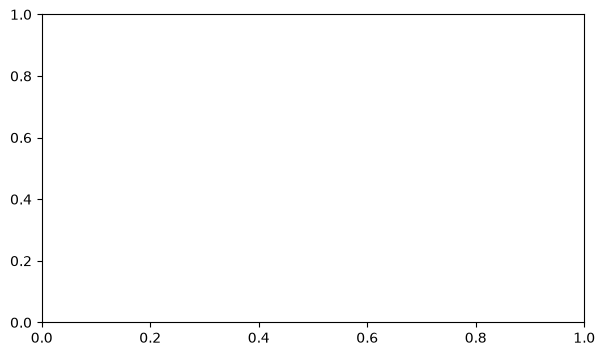

In [12]:
# Distribution plot 1: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 1: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

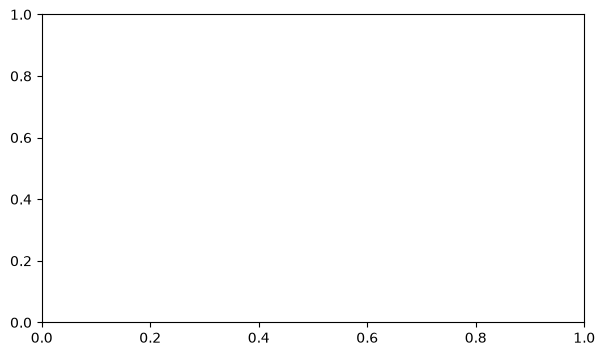

In [13]:
# Distribution plot 2: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 2: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

*(Add more distribution plots + notes if more features matter.)*

---
# Join: Open Air sensors → community areas
**Owner: Auon**

The Open Air data is per *sensor*, not per community area. To compare it with income, each sensor needs a community area.
Document how you did it and how many sensors/rows you could or couldn't match.

In [ ]:
# Join code here. Print match counts (matched / unmatched sensors) so they're traceable.


# STEP 1: Extract community names from sensor names.
# Example: "Near West Side 7" becomes "NEAR WEST SIDE"

air_join = air.with_columns(
    pl.col("sensor_name")
    .str.replace_all(r"\s+\d+$", "")
    .str.to_uppercase()
    .str.strip_chars()
    .str.replace("O'HARE", "OHARE")
    .alias("community")
)

# STEP 2: Standardize community names in the emissions data.

emis_join = emis.with_columns(
    pl.col("COMMUNITY")
    .str.to_uppercase()
    .str.strip_chars()
    .alias("community")
)

# STEP 3: Join using the community names.

joined = air_join.join(
    emis_join.select(
        "community", "INCOME", "ONROAD_CO2"
    ),
    on="community",
    how="left"
)

# STEP 4: Check how much data matched.

matched = joined.filter(pl.col("INCOME").is_not_null())
unmatched = joined.filter(pl.col("INCOME").is_null())

print("Total air rows:", air.height)
print("Matched rows:", matched.height)
print("Unmatched rows:", unmatched.height)
print("Matched sensors:", matched["datasourceid"].n_unique())
print("Unmatched sensors:", unmatched["datasourceid"].n_unique())
print("Matched community areas:", matched["community"].n_unique())



unmatched.group_by("community").agg(
    pl.len().alias("rows_affected"),
    pl.col("datasourceid").n_unique().alias("unique_sensors")
).sort("community")


**Join notes:** *(method, rows matched, rows unmatched, what you did with unmatched)*

- This means these 3 communities had some sensors that could not be matched. They were removed from the merged data. 

---
# Community Area Local Emission dataset
**Owner: Auon** · Primary dataset: `data/CommunityArea_...csv`

## Step 1 · Profile

In [15]:
print(emis.shape)
print(emis.schema)
emis.glimpse()

(77, 67)
Schema({'OBJECTID': Int64, 'COMMUNITY': String, 'CCA_TXT': Int64, 'CCA_NUM': Int64, 'ID': Int64, 'ID_1': Int64, 'GEO': String, 'TYPE': String, 'COUNTY': String, 'AREA': Int64, 'POP': Int64, 'JOBS': Float64, 'INCOME': Int64, 'HOUSEHOLDS': Int64, 'SF_HU': Float64, 'OCC_OWN': Float64, 'TREE_COV': Float64, 'IMP_SUR': Float64, 'GRC_MEM': String, 'RES_ELE_CO': Int64, 'NONRES_ELE': Int64, 'RES_NG_CO2': Float64, 'NONRES_NG_': Float64, 'ONROAD_CO2': Int64, 'ONROAD_COM': Int64, 'ONROAD_PAS': Int64, 'ONROAD_PUB': Float64, 'WASTE_CO2E': Int64, 'RES_ELE__1': Float64, 'NONRES_E_1': Float64, 'RES_NG_C_1': Float64, 'NONRES_NG1': Float64, 'ONROAD_C_1': Float64, 'WASTE_CO_1': Float64, 'EV_COUNT': Float64, 'EV_PERCENT': Float64, 'EV_STA_L2': String, 'EV_STA_DCF': String, 'EV_STA_TOT': String, 'WALKABILIY': Float64, 'TRAN_AVAIL': Float64, 'MODE_DRIVE': Float64, 'MODE_POOL': Float64, 'MODE_TRANS': Float64, 'MODE_WALK_': Float64, 'MODE_OTHER': Float64, 'RES_VMT': Float64, 'HH_VEHICLE': Float64, 'RE

In [16]:
emis.null_count()

OBJECTID,COMMUNITY,CCA_TXT,CCA_NUM,ID,ID_1,GEO,TYPE,COUNTY,AREA,POP,JOBS,INCOME,HOUSEHOLDS,SF_HU,OCC_OWN,TREE_COV,IMP_SUR,GRC_MEM,RES_ELE_CO,NONRES_ELE,RES_NG_CO2,NONRES_NG_,ONROAD_CO2,ONROAD_COM,ONROAD_PAS,ONROAD_PUB,WASTE_CO2E,RES_ELE__1,NONRES_E_1,RES_NG_C_1,NONRES_NG1,ONROAD_C_1,WASTE_CO_1,EV_COUNT,EV_PERCENT,EV_STA_L2,EV_STA_DCF,EV_STA_TOT,WALKABILIY,TRAN_AVAIL,MODE_DRIVE,MODE_POOL,MODE_TRANS,MODE_WALK_,MODE_OTHER,RES_VMT,HH_VEHICLE,RES_ELE_KW,NONRES_E_2,RES_NG_BTU,NONRES_N_1,RES_ELE__2,NONRES_E_3,RES_NG_B_1,NONRES_N_2,RES_ELE__3,RES_NG_B_2,SOLAR_POT,SOLSMART,Acres,Square_met,Sq_mi,Sq_ft,ft,Shape__Area,Shape__Length
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [17]:
emis.describe()

statistic,OBJECTID,COMMUNITY,CCA_TXT,CCA_NUM,ID,ID_1,GEO,TYPE,COUNTY,AREA,POP,JOBS,INCOME,HOUSEHOLDS,SF_HU,OCC_OWN,TREE_COV,IMP_SUR,GRC_MEM,RES_ELE_CO,NONRES_ELE,RES_NG_CO2,NONRES_NG_,ONROAD_CO2,ONROAD_COM,ONROAD_PAS,ONROAD_PUB,WASTE_CO2E,RES_ELE__1,NONRES_E_1,RES_NG_C_1,NONRES_NG1,ONROAD_C_1,WASTE_CO_1,EV_COUNT,EV_PERCENT,EV_STA_L2,EV_STA_DCF,EV_STA_TOT,WALKABILIY,TRAN_AVAIL,MODE_DRIVE,MODE_POOL,MODE_TRANS,MODE_WALK_,MODE_OTHER,RES_VMT,HH_VEHICLE,RES_ELE_KW,NONRES_E_2,RES_NG_BTU,NONRES_N_1,RES_ELE__2,NONRES_E_3,RES_NG_B_1,NONRES_N_2,RES_ELE__3,RES_NG_B_2,SOLAR_POT,SOLSMART,Acres,Square_met,Sq_mi,Sq_ft,ft,Shape__Area,Shape__Length
str,f64,str,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64
"""count""",77.0,"""77""",77.0,77.0,77.0,77.0,"""77""","""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""","""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0
"""null_count""",0.0,"""0""",0.0,0.0,0.0,0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",39.0,null,39.0,39.0,39.0,39.0,null,null,null,1918.675325,35667.376623,17058.376623,56199.935065,14840.584416,0.388701,0.477013,0.203896,0.683896,null,32010.74026,81611.454545,52842.155844,70227.25974,111441.545455,34579.194805,75666.831169,1195.532468,13110.753247,0.870909,2.118831,1.48,1.97,3.762208,0.37,40.402597,0.000779,null,null,null,0.973506,0.995065,0.562727,0.087792,0.26961,0.063896,0.015974,11651.844156,1.233377,8.2283e7,2.0978e8,994872.623377,1.3222e6,2238.506494,5444.805195,28.0,37.0,5611.675325,71.467532,null,null,110.859807,448633.720953,0.0,4.8290e6,2254.882918,1.4005e7,18171.098126
"""std""",22.371857,null,22.371857,22.371857,22.371857,22.371857,null,null,null,1261.796927,23675.47301,55488.711289,27028.194034,12009.835562,0.260341,0.194443,0.066157,0.104455,null,25537.457151,168943.697621,35075.852998,46615.757428,128429.41852,34800.151714,106291.232798,789.371479,8702.683339,0.191168,3.176218,0.0,0.0,5.276111,0.0,73.032664,0.002698,null,null,null,0.101226,0.030976,0.138018,0.039324,0.109586,0.082113,0.011269,3447.44413,0.405812,6.5643e7,4.3427e8,660381.577163,877647.637337,490.518271,8164.848884,0.0,0.0,1144.039191,13.336322,null,null,972.790856,3.9367e6,0.0,4.2375e7,19786.5173,9.2078e6,8235.420959
"""min""",1.0,"""ALBANY PARK""",1.0,1.0,1.0,1.0,"""Albany Park""","""Chicago Community Area""","""Cook""",372.0,2527.0,161.0,15396.0,1036.0,0.04,0.07,0.08,0.36,""" NA""",685.0,993.0,3744.0,4976.0,8842.0,2122.0,5728.0,180.0,929.0,0.09,0.14,1.48,1.97,1.19,0.37,0.0,0.0,""" -""",""" -""",""" -""",0.25,0.74,0.24,0.02,0.08,0.0,0.0,5747.0,0.46,1.760956e6,2.552379e6,70486.0,93676.0,242.0,351.0,28.0,37.0,698.0,44.0,""" -""","""NA""",0.0,0.0,0.0,0.0,0.0,2.8317e6,7412.072569
"""25%""",20.0,null,20.0,20.0,20.0,20.0,null,null,null,1141.0,18628.0,2540.0,34396.0,6850.0,0.15,0.36,0.16,0.63,null,16607.0,21857.0,27598.0,36678.0,49253.0,13516.0,30998.0,619.0,6847.0,0.73,0.87,1.48,1.97,1.8,0.37,6.0,0.0,null,null,null,1.0,1.0,0.48,0.06,0.18,0.02,0.01,8466.0,0.9,4.2688773e7,5.6181643e7,519592.0,690538.0,1876.0,2247.0,28.0,37.0,4943.0,62.0,null,null,0.0,0.0,0.0,0.0,0.0,8.3409e6,13088.284372
"""50%""",39.0,null,39.0,39.0,39.0,39.0,null,null,null,1828.0,29647.0,5144.0,51689.0,11278.0,0.31,0.45,0.2,0.69,null,24526.0,40192.0,43923.0,58373.0,74098.0,21797.0,45075.0,1076.0,10898.0,0.89,1.05,1.48,1.97,2.22,0.37,13.0,0.0,null,null,null,1.0,1.0,0

**What stands out:** *(your notes — only things you can point to in the outputs above)*

- It would appear as though the dataset contains a wide range of data pertaining to emissions and general demographic statistics. Looking at the website, column variables past Sq_mi seem to be purely for recordkeeping, and should be removed when we do our analysis. Several columns have the same value per row/community, and so they should also be removed.

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
|  |  |  |  |

In [ ]:
# Code that finds each anomaly (e.g. duplicate count, bad values). Rows affected must come from here.
print("Duplicate rows:", emis.is_duplicated().sum())
print("Unique communities:", emis["COMMUNITY"].n_unique())

constant_cols = [
    col for col in emis.columns
    if emis[col].n_unique() == 1
]

print(constant_cols)

print(
    emis["SOLAR_POT"]
    .value_counts()
    .sort("count", descending=True)
)

print(
    emis.filter(
        pl.col("SOLAR_POT") == "-"
    ).select("COMMUNITY", "SOLAR_POT")
)



This means there are 77 rows (entrees/observations), and 48 columns, or attributes each observation has. Each row is a community area. While there are no null values in the cleaned up dataset, SOLAR_POT is all dashes, so it could be a missing value placeholder.

## Step 3 · Distributions
One plot per feature that matters to the research questions.

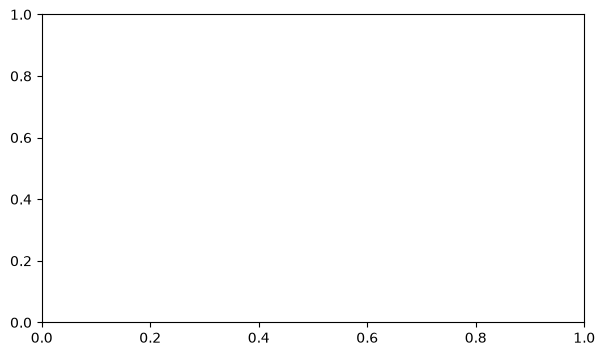

In [ ]:

# Distribution Plot 1: Number of Jobs

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(emis["JOBS"].to_list(), bins=100, edgecolor="black")

ax.set_xlabel("Number of Jobs")
ax.set_ylabel("Number of Community Areas")
ax.set_title("Distribution of Jobs Across Chicago Communities")

plt.tight_layout()
plt.show()


**Distribution 1: [feature name]**
- **Center: 10000 jobs** 
- **Spread: 500-120,000 jobs** 
- **Skew / shape: Heavily right skewed** 
- **Outliers: there are 8 community outliers**

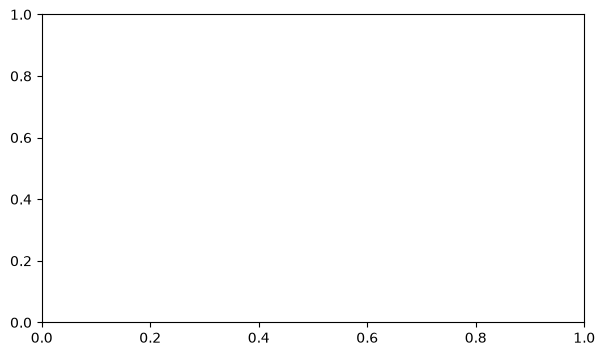

In [ ]:

import matplotlib.pyplot as plt

# Sort all 77 communities by emissions
all77 = emis.sort("ONROAD_CO2", descending=True)

fig, ax = plt.subplots(figsize=(24, 9))

ax.bar(
    all77["COMMUNITY"].to_list(),
    all77["ONROAD_CO2"].to_list(),
    width=0.75
)

ax.set_xlabel("Chicago Community Area", fontsize=12)
ax.set_ylabel("On-Road CO2 Emissions (dataset units)", fontsize=12)
ax.set_title(
    "On-Road CO2 Emissions Across Chicago's 77 Community Areas",
    fontsize=16
)

# Rotate community names vertically
plt.xticks(rotation=90, fontsize=12)

ax.tick_params(axis="y", labelsize=11)

# Make the grid easier to read
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


**Distribution 2: On-Road CO₂ Emissions by Chicago Community Area**
- **Center: median is 74,098, and the mean is approximately 111,442** 
- **Spread: Emissions range from 8,842 to 679,090, with an interquartile range (IQR) of 66,979.** 
- **Skew / shape: strongly right-skewed** 
- **Outliers: 5 high outliers: Loop (679,090), Near North Side (639,481), O'Hare (572,165), Near West Side (533,627), and South Lawndale (246,137), using IQRx1.5**

*(Add more distribution plots + notes if more features matter.)*

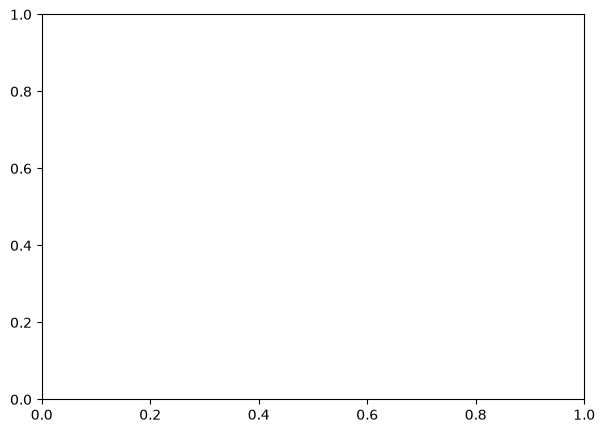

In [ ]:
# R4: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.

cols = [
    "POP",
    "JOBS",
    "INCOME",
    "ONROAD_CO2",
    "NONRES_ELE"
]

corr_df = emis.select(cols).corr()

corr_df = corr_df.with_columns(
    pl.Series("Variable", cols)
).select(["Variable"] + cols)

print(corr_df)


- Simple correlation matrix between some potentially relevant variables. (Note NONRES_ELE and JOBS, NONRES_ELE and ONROAD_CO2).

---
# Income dataset
**Owner: Jesus** · Secondary dataset: `data/Chicago_Median_Income_By_Community_Area.csv`

In [22]:
print(income.shape)
print(income.schema)
income.glimpse()

(78, 5)
Schema({'Layer': String, 'Name': String, 'GEOID': Int64, 'INC_2020-2024': String, 'PCI_2020-2024': String})
Rows: 78
Columns: 5
$ Layer         <str> null, 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area'
$ Name          <str> null, 'Rogers Park', 'Norwood Park', 'Jefferson Park', 'Forest Glen', 'North Park', 'Albany Park', 'Portage Park', 'Irving Park', 'Dunning'
$ GEOID         <i64> null, 1, 10, 11, 12, 13, 14, 15, 16, 17
$ INC_2020-2024 <str> 'Median household income, 2020-2024', '64982.84252006701', '117196.55685334843', '99973.6803472109', '143029.53249393537', '70550.56287265262', '89407.95574996143', '94793.33527687968', '95607.64589337097', '90515.97830108434'
$ PCI_2020-2024 <str> 'Per capita income, 2020-2024', '41401.316073557224', '53787.75290118216', '51002.44814039693', '72837.37767535771', '39578.42721913615', '44491.796264110155', '44349.38581261013',

In [23]:
income.null_count()

Layer,Name,GEOID,INC_2020-2024,PCI_2020-2024
u32,u32,u32,u32,u32
1,1,1,0,0


In [24]:
income.describe()

statistic,Layer,Name,GEOID,INC_2020-2024,PCI_2020-2024
str,str,str,f64,str,str
"""count""","""77""","""77""",77.0,"""78""","""78"""
"""null_count""","""1""","""1""",1.0,"""0""","""0"""
"""mean""",null,null,39.0,null,null
"""std""",null,null,22.371857,null,null
"""min""","""Community area""","""Albany Park""",1.0,"""114817.95318301945""","""103268.59585138268"""
"""25%""",null,null,20.0,null,null
"""50%""",null,null,39.0,null,null
"""75%""",null,null,58.0,null,null
"""max""","""Community area""","""Woodlawn""",77.0,"""Median household income, 2020-…","""Per capita income, 2020-2024"""


**What stands out:** *(your notes — only things you can point to in the outputs above)*

-

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
|  |  |  |  |

In [25]:
# Code that finds each anomaly (e.g. duplicate count, bad values). Rows affected must come from here.

## Step 3 · Distributions
One plot per feature that matters to the research questions.

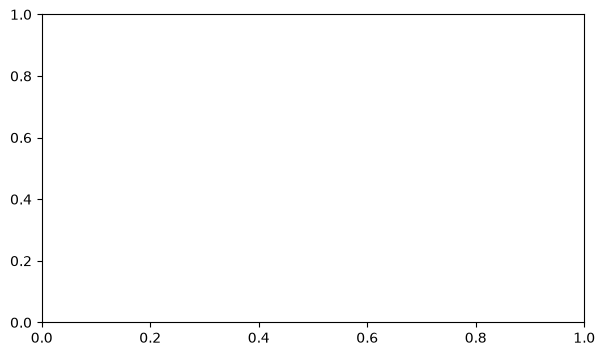

In [26]:
# Distribution plot 1: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 1: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

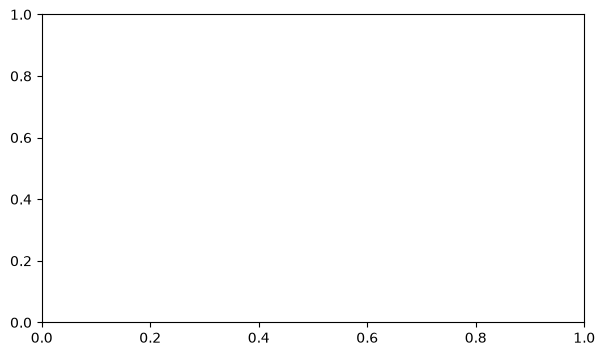

In [27]:
# Distribution plot 2: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 2: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

*(Add more distribution plots + notes if more features matter.)*

---
# Step 4 · Relationships
**Owner: Ani** · *Join `income` and `emis` on community area name (see `Ani_Data.ipynb`).*


In [28]:
# ---- Data prep: clean & merge income + emissions ----
income_clean = (
    income
    .filter(pl.col("GEOID").is_not_null())
    .with_columns([
        pl.col("GEOID").cast(pl.Float64).cast(pl.Int64).alias("GEOID"),
        pl.col("INC_2020-2024").cast(pl.Float64).alias("median_household_income"),
        (pl.col("Name").str.to_uppercase().str.replace("'", "", literal=True)).alias("join_key")
    ])
)

emis_clean = emis.with_columns([
    (pl.col("COMMUNITY").str.to_uppercase().str.replace("'", "", literal=True)).alias("join_key")
])

merged = income_clean.join(emis_clean, on="join_key", how="inner")

emission_cols = ["RES_ELE_CO", "NONRES_ELE", "RES_NG_CO2", "NONRES_NG_", "ONROAD_CO2", "WASTE_CO2E"]
merged = merged.with_columns(pl.sum_horizontal(emission_cols).alias("total_co2"))
merged = merged.with_columns((pl.col("total_co2") / pl.col("POP")).alias("co2_per_capita"))

print(merged.shape)

(77, 76)


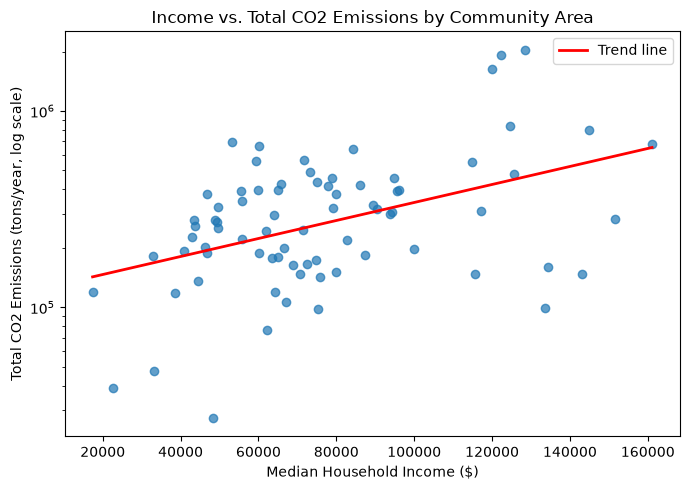

In [29]:
# R3: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.
fig, ax = plt.subplots(figsize=(7, 5))

x = merged["median_household_income"].to_numpy()
y = merged["total_co2"].to_numpy()
ax.scatter(x, y, alpha=0.7)
ax.set_yscale("log")

z = np.polyfit(x, np.log10(y), 1)
x_line = np.linspace(x.min(), x.max(), 100)
y_line = 10 ** np.polyval(z, x_line)
ax.plot(x_line, y_line, color="red", linewidth=2, label="Trend line")

ax.set_xlabel("Median Household Income ($)")
ax.set_ylabel("Total CO2 Emissions (tons/year, log scale)")
ax.set_title("Income vs. Total CO2 Emissions by Community Area")
ax.legend()
plt.tight_layout()
plt.show()

### R3: So what?



**What it shows:**
There's a loose positive trend, higher income areas generally emit more. But it's noisy. Some $50k-$65k areas emit as much as the wealthiest ones, and the top 3 emitters aren't even the richest areas.

**Why it matters for our research questions:**
Income alone isn't explaining much here, something else is driving the outliers. That points to other factors (likely commercial/industrial activity, building density, or land use) playing a bigger role than income by itself, which matters if we're trying to explain emissions patterns across Chicago community areas.

**Did we expect this? (expected / unexpected / in between):**
In between. Some correlation was expected (more money, more commercial activity nearby), but it's weaker and noisier than we thought it'd be.
### R3: What next?
- **Next question this points to** *(extra comparison, subgroup to split out, dataset to join, expert to ask)*:
Join in land use / zoning data (commercial vs. industrial vs. residential share per community area) to see if that explains the outliers better than income does. Also worth checking population density and number of businesses per area, since a few high-emission, lower-income areas could be driven by industrial corridors rather than household consumption.

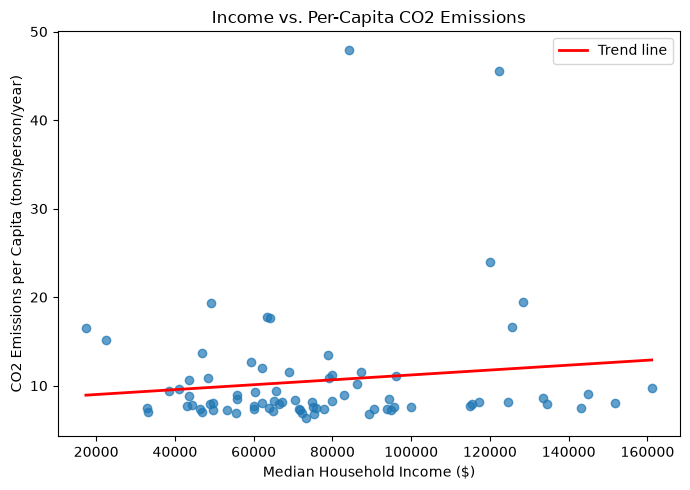

In [32]:
# R3: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.
fig, ax = plt.subplots(figsize=(7, 5))

x = merged["median_household_income"].to_numpy()
y = merged["co2_per_capita"].to_numpy()
ax.scatter(x, y, alpha=0.7)

z = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
y_line = np.polyval(z, x_line)
ax.plot(x_line, y_line, color="red", linewidth=2, label="Trend line")

ax.set_xlabel("Median Household Income ($)")
ax.set_ylabel("CO2 Emissions per Capita (tons/person/year)")
ax.set_title("Income vs. Per-Capita CO2 Emissions")
ax.legend()
plt.tight_layout()
plt.show()

## R3: So what? (Step 5)

**What it shows:**
Once you divide by population, the trend from the raw totals chart disappears. Most community areas sit between 7-20 tons/person no matter their income, from under $20k to over $150k. No real slope. The handful of outliers (45-48 tons/person) are O'Hare and the Loop, both have small residential populations relative to their emissions, O'Hare's pollution comes from airport operations, the Loop's from commercial office space.

**Why it matters for our research questions:**
This lowers confidence that income directly drives pollution exposure. If it did, per-capita emissions should rise with income, and they don't. Land use looks like the actual driver, commercial and industrial zones emit way more than their resident population alone would suggest, regardless of income.

**Did we expect this? (expected / unexpected / in between):**
Unexpected. The raw totals chart suggested a positive income relationship, but once you control for population, that relationship basically vanishes.

### R3: What next? (Step 6)
- **Next question this points to** *(extra comparison, subgroup to split out, dataset to join, expert to ask)*:
Pull out O'Hare and the Loop as separate cases (airport ops vs. commercial office emissions) rather than lumping them in with residential community areas, they're skewing the picture. Then join zoning/land-use data to split areas by commercial vs. industrial vs. residential share and re-run the per-capita comparison within each group, to see if income matters once land use is held constant.

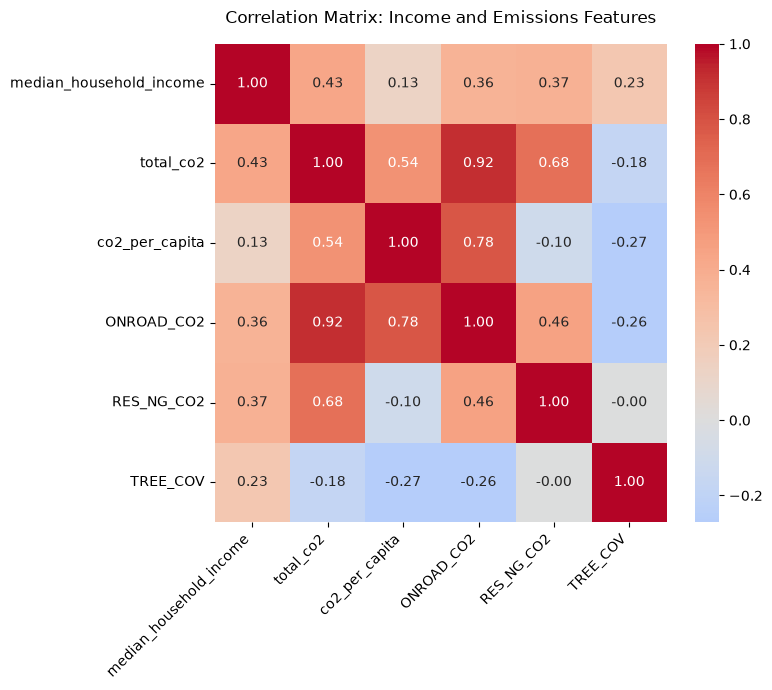

In [ ]:
# R3: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.
fig, ax = plt.subplots(figsize=(8, 7))

corr_cols = ["median_household_income", "total_co2", "co2_per_capita", "ONROAD_CO2", "RES_NG_CO2", "TREE_COV"]
corr_matrix = merged.select(corr_cols).to_pandas().corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("Correlation Matrix: Income and Emissions Features", pad=15)
plt.tight_layout()
plt.show()

## R3: So what? (Step 5)

**What it shows:**
Per-capita income correlates with total_co2 more than household income does (0.62 vs 0.43), so per-capita is probably the better variable to use going forward. Biggest finding: on-road emissions correlate with total CO2 at 0.92. Residential gas only correlates at 0.68. Tree cover is slightly negatively correlated with emissions and slightly positively correlated with income.

**Why it matters for our research questions:**
That 0.92 correlation means total emissions are basically a transportation story, not a "wealthy households use more energy" story. It backs up what the per-capita chart already suggested, land use and activity type (traffic, commercial/industrial zones) matter more than income itself. The tree cover pattern, small as it is, hints at an environmental equity angle worth mentioning.

**Did we expect this? (expected / unexpected / in between):**
In between. Expected income and emissions to correlate somewhat, but the strength of the transportation link (0.92) and the weakness of the direct income link were bigger than anticipated.

### R3: What next? (Step 6)
- **Next question this points to** *(extra comparison, subgroup to split out, dataset to join, expert to ask)*:
Normalize by population instead of using raw totals, and look at transportation emissions separately from residential since they're clearly driven by different things. Also worth digging into the tree cover/income relationship more, since it could point to an environmental equity story.